# Regression Trees
Regression trees are a type of decision tree used to predict continuous numerical values rather than categorical classes. They use measures such as Sum of Squared Residuals (SSR) to find the best split and predict the mean target value in each leaf.

### Set up of data

We're taking the classic Titanic dataset.

In [146]:
import numpy as np
import pandas as pd
import math
titanic = pd.read_csv('Titanic-Dataset.csv')

titanic.head()

# remove irrelevant columns
titanic = titanic.drop(["PassengerId", "Name", "Cabin", "Ticket"], axis =1)

#handle missing values
titanic["Age"] = titanic["Age"].fillna(titanic["Age"].median())
titanic["Embarked"] = titanic["Embarked"].fillna(titanic["Embarked"].mode()[0])

# change string columns to numbers
sex = {"female": 1, "male": 0}
embark = {"S": 0, "C": 1, "Q": -1}

titanic["Sex"] = titanic["Sex"].map(sex)
titanic["Embarked"] = titanic["Embarked"].map(embark)

# changing the name
data = titanic

data.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,0,22.0,1,0,7.2500,0
1,1,1,1,38.0,1,0,71.2833,1
2,1,3,1,26.0,0,0,7.9250,0
3,1,1,1,35.0,1,0,53.1000,0
4,0,3,0,35.0,0,0,8.0500,0


Setting up the features and the target.

In [147]:
features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Embarked"]
target = ["Fare"]

# split into training and testing 80/20
data = data.sample(frac=1).reset_index(drop=True)
split = int(0.8 * len(data)) 

train = data[:split] 
test = data[split:] 

### Sum of Squared Residuals (SSR)
SSR is the measure used by regression trees to evaluate possible splits and select the ones that minimize the prediction error within the resulting groups.

#### $SSR=\sum_{i=1}^n (y_i - \bar y)^2$


n = number of observations

$y_i$ = target value 

$\bar y$ = mean of the target values

![alt text](images/image1.svg)

In [ ]:
def ssr(target):
    # Calculate the mean of the target values
    mean = np.mean(target)

    # Calculate the squared residuals
    ssr = 0
    
    #LIVE CODE
    for value in target:
        residual = value - mean
        ssr += residual**2

    return ssr

# Example
fares = [10, 12, 14, 16, 18]
print("SSR for fares: ", ssr(fares))

SSR for fares:  40.0


We can use SSR as is or we can also use MSE (Mean Squared Error) as the splitting criteria. 

$MSE=\Large\frac{SSR}{n}$

For this assignment, we will use SSR as the splitting criteria. 


### Weighted SSR
After splitting the data into left and right groups, we calculate the SSR separately for each group and add the results together. This gives us the total remaining error after the split. The goal is to find the threshold that minimizes this combined SSR, as this means the target values within each resulting group are closer to their respective mean values, resulting in more accurate predictions.

$SSR_{split}=SSR_{left} + SSR_{right}$




In [ ]:
def weighted_ssr_num(data, feature, target, min_samples_leaf=1):
    # Finds the best threshold for one numeric feature using SSR.
    # It returns (threshold, weighted_ssr) or (None, inf) if no valid split exists

    values = sorted(data[feature].unique())
    best_threshold = None
    best_score = float("inf")
    
    #LIVE CODE
    for i in range(len(values) - 1):
        threshold = (values[i] + values[i + 1]) / 2

        left = data[data[feature] <= threshold]
        right = data[data[feature] > threshold]
        
        # To prevent overfitting, we set a minimum number of samples required in each leaf node.
        # If after splitting, either left or right has fewer samples than this minimum, we skip this threshold.
        if len(left) < min_samples_leaf or len(right) < min_samples_leaf: 
            continue

        # Calculate the weighted sum of squared residuals for this split
        score = (
            ssr(left[target].values) +
            ssr(right[target].values)
        )

        if score < best_score:
            best_threshold = threshold
            best_score = score

    return best_threshold, best_score

### Finding where to split
To find the best split for a numerical feature, we test different thresholds between its unique sorted values. For each threshold, the data is divided into two groups: values less than or equal to the threshold and values greater than it. We then calculate the weighted SSR for each split and select the threshold that produces the lowest total SSR.

In [150]:
def find_split(data, features, target, min_samples_leaf=1):
    # Finds the best feature and threshold using SSR

    #Calculates the SSR of the original group before splitting
    parent = ssr(data[target].values)
    best = None

    # Iterate through each feature to find the best split
    for feature in features:
        threshold, score = weighted_ssr_num(
            data, feature, target, min_samples_leaf
        )
        # If a valid threshold is found and it improves the score, update the best split
        if threshold is not None and (best is None or score < best["score"]):
            best = {
                "feature": feature,
                "threshold": threshold,
                "score": score,
                "gain": parent - score #calculates how much the SSR decreases after the split
            }

    return best

In [152]:
def data_split(data, feature, threshold):
    # Divides the DataFrame into left and right groups

    left = data[data[feature] <= threshold]
    right = data[data[feature] > threshold]

    return left, right

#### Displaying the result of the first (Root) split 

In [151]:
# calculates the total SSR of the training dataset before any split
root_ssr = ssr(train[target].values.ravel())

rows = []

for feature in features:
    threshold, score = weighted_ssr_num(
        train, feature, target
    )

    score = score.item() # Converts the NumPy value into a regular Python number

    rows.append({
        "Feature": feature,
        "Best threshold": threshold,
        "SSR": round(score, 2),
        "SSR reduction": round(float(root_ssr - score), 2),
        "% of SSR removed": round(
            float(100 * (root_ssr - score) / root_ssr), 2
        )
    })

results = pd.DataFrame(rows).sort_values("SSR")

print(f"Root SSR: {float(root_ssr):.2f}")
display(results)

Root SSR: 1835291.75


,Feature,Best threshold,SSR,SSR reduction,% of SSR removed
0,Pclass,1.50,1213492.65,621799.10,33.88
5,Embarked,0.50,1720301.18,114990.58,6.27
4,Parch,0.50,1735132.91,100158.85,5.46
2,Age,34.75,1776654.31,58637.44,3.19
3,SibSp,0.50,1780801.52,54490.23,2.97
1,Sex,0.50,1788827.63,46464.13,2.53


### Graph Structure

Each node in the tree has an ID to identify its parent and children, a print method to display its information, and a resolve method to process an incoming data row and determine its prediction.

**Nodes**
Nodes represent the decision points of the tree. Each node stores the feature used for splitting, the threshold condition, the SSR of the parent data, and the SSR reduction (gain) achieved by the split.

Resolve checks the incoming data row against the node's condition (feature <= threshold) and passes the row to the corresponding child node. The data row continues down the tree until it reaches a leaf.

**Leaves**
Leaves are the endpoints of the tree branches. They store the prediction for the data reaching that leaf.

When a leaf is created, it receives the mean of the target values from its corresponding subset of data. This mean represents the predicted value for all observations reaching that leaf.

Resolve returns this prediction.

In [153]:
import random

# Base class for all nodes in the tree
class Graph_Node:
    def __init__(self):
        self.id = random.randrange(100, 999) #unique identifier for the node, will be used when visualizing the tree

    def print(self):
        print(f"ID: {self.id}")

    def resolve(self, x=None):
        return None

# Class representing a decision node in the regression tree
class Node(Graph_Node):
    def __init__(self, feature: str, threshold, ssr, gain):
        self.feature = feature
        self.threshold = threshold
        self.ssr = ssr
        self.gain = gain #how much SSR decreases after splitting a node (= parent SSR - child SSR). A higher gain indicates a better split.

        self.id = random.randrange(100, 999)

    child1 : Graph_Node
    child2 : Graph_Node

    def print(self):
        print(f"ID: {self.id}")
        print(f"Feature: {self.feature}")
        print(f"Threshold: {self.threshold}")
        print(f"SSR: {self.ssr}")
        print(f"SSR reduction: {self.gain}")

        print(f"First child :  ({self.id})")
        self.child1.print()
        
        print(f"\nSecond child :  ({self.id})")
        self.child2.print()

    def set_children(self, child1: Graph_Node, child2: Graph_Node):
        self.child1 = child1
        self.child2 = child2

    def get_child1(self):
        return self.child1

    def get_child2(self):
        return self.child2
    
    #returns True is the observation belongs to the left child, False otherwise
    def get_if_split(self, x):
        return x[self.feature] <= self.threshold
    
    # returns the prediction for the observation x by traversing the tree from the current node down to a leaf node.
    def resolve(self, x):
        if self.get_if_split(x):
            return self.child1.resolve(x)

        return self.child2.resolve(x)

# Class representing a leaf node in the regression tree
class Leaf(Graph_Node):
    def __init__(self, prediction):
        self.prediction = prediction
        self.id = random.randrange(100, 999)

    def print(self):
        print(f"Leaf: ({self.id})")
        print(f"Prediction: {self.prediction}")

    def resolve(self, x=None):
        return self.prediction

### The Tree
We create the root by calling build_nodes on the training data. The function finds the best split, creates a decision node, divides the data, and recursively builds its children.

For each subset of data, we first check the stopping conditions:
- Has the maximum depth been reached (current_depth >= max_depth)?
- Are there too few data points to split the node (len(data) < min_samples_split)?
- Is there no valid split available?
- Does the best split provide no positive SSR reduction (gain <= 0)?

If any of these conditions are met, we create a leaf instead of another decision node. The leaf receives the mean of the target values in that subset as its prediction.

We also enforce min_samples_leaf when evaluating possible splits, ensuring that each resulting child contains at least the specified number of data points.

**Prediction**

To predict new data, each row is passed to the root node's resolve method. It follows the appropriate branches according to the splitting conditions until it reaches a leaf.

The leaf returns its stored mean target value as the prediction.

In [ ]:
# Class representing the regression tree
class Tree:
    def __init__(self, data: pd.DataFrame, features: list,
                target: list, max_depth: int, min_samples_split: int, min_samples_leaf: int):

        self.data = data
        self.features = features
        self.target = target
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split # Min samples required in a node to allow further splitting
        self.min_samples_leaf = min_samples_leaf # Min samples required for any resulting child node to remain a leaf
        self.root = None

    def get_root(self):
        return self.root

    def build_tree(self):
        self.root = self.build_nodes(self.data, current_depth=0)

    def build_nodes(self, data: pd.DataFrame, current_depth: int):
        # Calculate the mean fare for the current group
        prediction = np.mean(data[self.target].values).item()

        # Calculate the SSR of the current group
        node_ssr = ssr(data[self.target].values).item()

        # Stopping Conditions:
        # Stop if there are too few observations to split
        if len(data) < self.min_samples_split:
            return Leaf(prediction)

        # Stop if the maximum depth has been reached
        if current_depth >= self.max_depth:
            return Leaf(prediction)

        # Find the best feature and threshold
        split = find_split(
            data, self.features, self.target,
            self.min_samples_leaf
        )           
        
        # Stop if no valid split can be found
        if split is None:
            return Leaf(prediction)

        # Calculate the SSR reduction
        gain = np.asarray(split["gain"]).item()

        # Stop if the split does not improve SSR
        if gain <= 0:
            return Leaf(prediction)

        # Create the decision node
        parent = Node(
            split["feature"],
            split["threshold"],
            node_ssr,
            gain
        )

        # Divide the dataset into two groups
        child_data_1, child_data_2 = data_split(
            data,
            split["feature"],
            split["threshold"]
        )

        # Recursively build the two children
        current_depth += 1

        parent.set_children(
            self.build_nodes(child_data_1, current_depth),
            self.build_nodes(child_data_2, current_depth)
        )

        return parent

    def predict(self, new_data: pd.DataFrame):

        predictions = []

        # Go through each observation in the new dataset
        for index, row in new_data.iterrows():

            # Convert the row into a dictionary
            item = row.to_dict()

            # Follow the tree and get the prediction
            prediction = self.root.resolve(item)

            # Store the prediction
            predictions.append(prediction)

        return pd.Series(predictions, index=new_data.index, name="Prediction")

    def print(self):
            self.root.print()


### Let's Build

Let us build our tree and print our nodes.

In [155]:
# Creating a regression tree
regression_tree = Tree(
    train,
    features,
    target,
    max_depth=3,
    min_samples_split=20,
    min_samples_leaf=5
)

regression_tree.build_tree()
regression_tree.print()

ID: 705
Feature: Pclass
Threshold: 1.5
SSR: 1835291.7535474426
SSR reduction: 621799.1001082431
First child :  (705)
ID: 271
Feature: Parch
Threshold: 0.5
SSR: 1131698.427972541
SSR reduction: 155619.18910879432
First child :  (271)
ID: 794
Feature: Sex
Threshold: 0.5
SSR: 612964.36752024
SSR reduction: 53204.56596144033
First child :  (794)
Leaf: (252)
Prediction: 51.429500000000004

Second child :  (794)
Leaf: (703)
Prediction: 93.79932040816325

Second child :  (271)
ID: 633
Feature: Age
Threshold: 36.5
SSR: 363114.87134350656
SSR reduction: 21639.02973493171
First child :  (633)
Leaf: (693)
Prediction: 160.24275217391306

Second child :  (633)
Leaf: (407)
Prediction: 112.3546875

Second child :  (705)
ID: 941
Feature: SibSp
Threshold: 0.5
SSR: 81794.22546665865
SSR reduction: 21204.43114425632
First child :  (941)
ID: 678
Feature: Parch
Threshold: 0.5
SSR: 26133.827983126223
SSR reduction: 3401.242344042181
First child :  (678)
Leaf: (739)
Prediction: 10.103514161849711

Second chi

## Prediction

In [156]:
def compare(df: pd.DataFrame, target: str, predicted: str):

    # Calculate the difference between actual and predicted values
    df["Difference"] = df[target] - df[predicted]

    # Calculate the absolute difference
    df["Absolute Difference"] = abs(df["Difference"])

    return df

In [140]:
# Display the comparison between actual and predicted values
prediction = regression_tree.predict(test[features])

comparison = test.copy()

comparison["Prediction"] = prediction

comparison = compare(comparison, "Fare", "Prediction")

display(comparison[["Fare", "Prediction", "Difference", "Absolute Difference"]].head(10))

,Fare,Prediction,Difference,Absolute Difference
712,57.9792,93.765479,-35.786279,35.786279
713,26.0000,17.818942,8.181058,8.181058
714,26.0000,24.801014,1.198986,1.198986
715,15.7417,24.801014,-9.059314,9.059314
716,7.2292,10.173174,-2.943974,2.943974
717,30.6958,100.965957,-70.270157,70.270157
718,6.8583,10.173174,-3.314874,3.314874
719,7.2292,24.801014,-17.571814,17.571814
720,16.7000,24.801014,-8.101014,8.101014
721,0.0000,55.766021,-55.766021,55.766021


## Sklearn

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Actual values
y_true = test[target].values.ravel()

# Predictions from our own regression tree
custom_predictions = regression_tree.predict(test[features]).values

# Evaluation
custom_mae = mean_absolute_error(y_true, custom_predictions) # The average absolute difference between the actual and predicted values
custom_mse = mean_squared_error(y_true, custom_predictions) # The average of the squared differences between actual and predicted values
custom_rmse = np.sqrt(custom_mse) # Brings the result back to the original unit of the target variable
custom_r2 = r2_score(y_true, custom_predictions) # How much better the model performs than the mean baseline

print("Our Regression Tree")
print("MAE:", custom_mae)
print("MSE:", custom_mse)
print("RMSE:", custom_rmse)
print("R²:", custom_r2)

Our Regression Tree
MAE: 16.366174019686497
MSE: 1007.7326824126951
RMSE: 31.744805597336633
R²: 0.4980799579411952


In [159]:
from sklearn.tree import DecisionTreeRegressor

# Separate features and target
X_train = train[features]
X_test = test[features]

y_train = train[target].values.ravel()
y_test = test[target].values.ravel()

# Create the Scikit-learn regression tree
regressor = DecisionTreeRegressor(
    max_depth=3,
    min_samples_split=20,
    min_samples_leaf=5,
    random_state=1
)

# Train the model
regressor.fit(train[features], train[target].values.ravel())

# Predictions from Scikit-learn
sklearn_predictions = regressor.predict(test[features])

# Evaluation
sklearn_mae = mean_absolute_error(y_true, sklearn_predictions)
sklearn_mse = mean_squared_error(y_true, sklearn_predictions)
sklearn_rmse = np.sqrt(sklearn_mse)
sklearn_r2 = r2_score(y_true, sklearn_predictions)

print("\nScikit-learn Regression Tree")
print("MAE:", sklearn_mae)
print("MSE:", sklearn_mse)
print("RMSE:", sklearn_rmse)
print("R²:", sklearn_r2)

# Comparing the performance of our regression tree with Scikit-learn's implementation
comparison = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R²"],
    "Our Tree": [custom_mae, custom_mse, custom_rmse, custom_r2],
    "Scikit-learn": [sklearn_mae, sklearn_mse, sklearn_rmse, sklearn_r2]
})

display(comparison)



Scikit-learn Regression Tree
MAE: 16.366174019686497
MSE: 1007.7326824126951
RMSE: 31.744805597336633
R²: 0.4980799579411952


,Metric,Our Tree,Scikit-learn
0,MAE,16.366174,16.366174
1,MSE,1007.732682,1007.732682
2,RMSE,31.744806,31.744806
3,R²,0.498080,0.498080


## Visualisation of the decision path


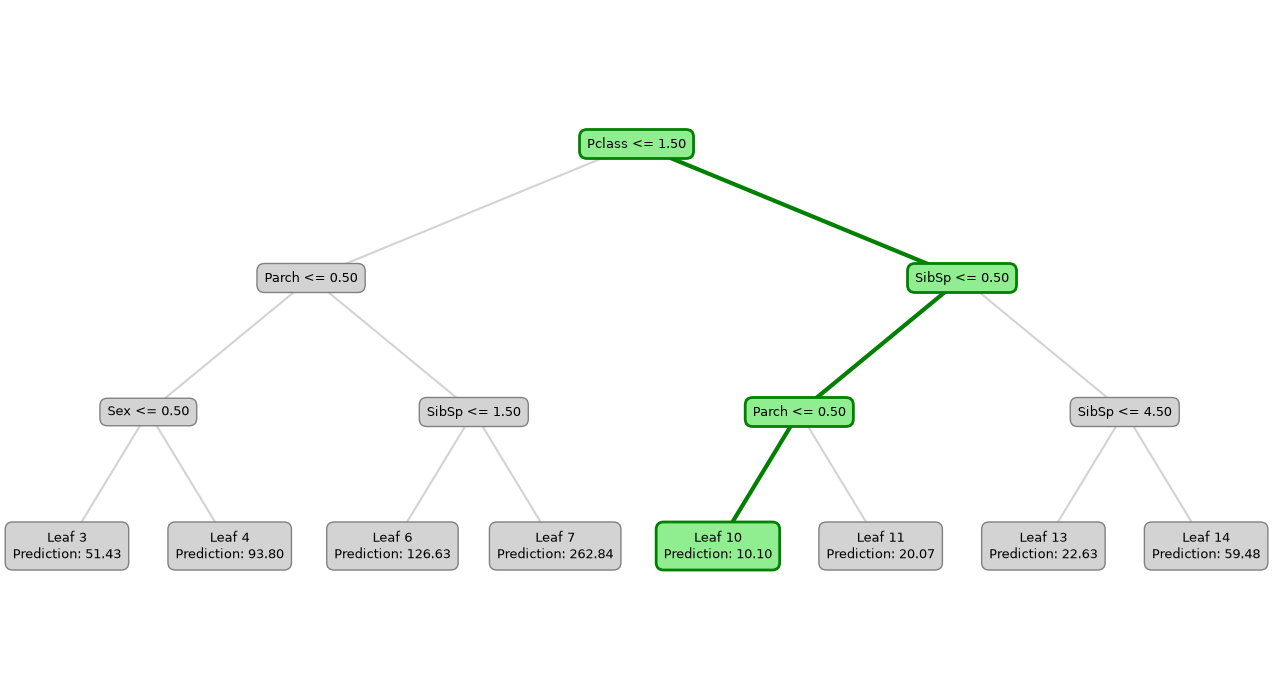

In [160]:
from sklearn.tree import DecisionTreeRegressor

tree_reg_small = DecisionTreeRegressor(
    max_depth=3,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=1
)

tree_reg_small.fit(X_train, y_train)


import matplotlib.pyplot as plt

# Select one passenger
passenger = X_test.iloc[[0]]

# Get the nodes visited by this passenger
path = tree_reg_small.decision_path(passenger)
node_ids = path.indices
visited = set(node_ids)

# Access the tree structure
tree_structure = tree_reg_small.tree_

# Store node positions
positions = {}
leaf_counter = [0]

def get_positions(node_id, depth=0):
    left = tree_structure.children_left[node_id]
    right = tree_structure.children_right[node_id]

    if left == right:
        x = leaf_counter[0]
        leaf_counter[0] += 1
    else:
        left_x = get_positions(left, depth + 1)
        right_x = get_positions(right, depth + 1)
        x = (left_x + right_x) / 2

    positions[node_id] = (x, -depth)
    return x

get_positions(0)

# Create visualization
fig, ax = plt.subplots(figsize=(13, 7))

# Draw branches
for node_id in range(tree_structure.node_count):
    left = tree_structure.children_left[node_id]
    right = tree_structure.children_right[node_id]

    if left == right:
        continue

    for child in [left, right]:
        x1, y1 = positions[node_id]
        x2, y2 = positions[child]

        color = "green" if child in visited else "lightgray"
        width = 3 if child in visited else 1.5

        ax.plot([x1, x2], [y1, y2],
                color=color, linewidth=width, zorder=1)

# Draw nodes
for node_id in range(tree_structure.node_count):
    x, y = positions[node_id]

    left = tree_structure.children_left[node_id]
    right = tree_structure.children_right[node_id]

    if left == right:
        label = f"Leaf {node_id}\nPrediction: {tree_structure.value[node_id][0][0]:.2f}"
    else:
        feature_id = tree_structure.feature[node_id]
        feature_name = features[feature_id]
        threshold = tree_structure.threshold[node_id]
        label = f"{feature_name} <= {threshold:.2f}"

    color = "lightgreen" if node_id in visited else "lightgray"

    ax.text(
        x, y, label,
        ha="center", va="center", fontsize=9,
        bbox=dict(
            boxstyle="round,pad=0.6",
            facecolor=color,
            edgecolor="green" if node_id in visited else "gray",
            linewidth=2 if node_id in visited else 1
        ),
        zorder=2
    )

ax.axis("off")
ax.set_ylim(-4, 1)
plt.tight_layout()
plt.show()



##  Analysis of Hyperparameters Impact in Sklearn
#### Individual hyperparameter impact
Lower RMSE indicates better performance.


In [161]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import cross_val_score
import matplotlib.pyplot as plt
import numpy as np

# Prepare training data
X_train = train[features]
y_train = train[target].values.ravel()

# Fixed baseline parameters. Only the parameter being tested will be modified. 
baseline_depth = 3
baseline_split = 20
baseline_leaf = 1

max_depth - the maximum depth of the tree

In [162]:
# Values of max_depth to test
depth_values = range(1, 11)

depth_rmse = []

for depth in depth_values:

    # Create a tree with the current max_depth
    regressor = DecisionTreeRegressor(
        max_depth=depth,
        min_samples_split=baseline_split,
        min_samples_leaf=baseline_leaf,
        random_state=1
    )

    # Perform 5-fold cross-validation
    scores = cross_val_score(
        regressor,
        X_train,
        y_train,
        cv=5,
        scoring="neg_mean_squared_error"
    )

    # Convert negative MSE to RMSE
    rmse = np.sqrt(-scores.mean())

    depth_rmse.append(rmse)

# Display results
depth_results = pd.DataFrame({
    "Max Depth": list(depth_values),
    "RMSE": depth_rmse
})

depth_results["RMSE"] = depth_results["RMSE"].round(2)

display(depth_results.sort_values("RMSE").reset_index(drop=True))

,Max Depth,RMSE
0,5,40.00
1,8,40.35
2,9,40.36
3,10,40.36
4,7,40.38
5,6,40.45
6,2,41.25
7,1,41.88
8,4,42.00
9,3,42.37


The best result was achieved with a maximum depth of 3. Increasing the depth beyond this did not improve performance, instead, RMSE  increased. A relatively shallow tree is sufficient for this dataset.

min_samples_split - the minimum number of observations required in a node before it can be split

In [163]:
# Values of min_samples_split to test
split_values = [2, 5, 10, 20, 30, 50, 75, 100]

split_rmse = []

for minimum in split_values:

    regressor = DecisionTreeRegressor(
        max_depth=baseline_depth,
        min_samples_split=minimum,
        min_samples_leaf=baseline_leaf,
        random_state=1
    )

    scores = cross_val_score(
        regressor,
        X_train,
        y_train,
        cv=5,
        scoring="neg_mean_squared_error"
    )

    rmse = np.sqrt(-scores.mean())
    split_rmse.append(rmse)

# Display results
split_results = pd.DataFrame({
    "Min Samples Split": split_values,
    "RMSE": split_rmse
})

split_results["RMSE"] = split_results["RMSE"].round(2)

display(split_results.sort_values("RMSE").reset_index(drop=True))

,Min Samples Split,RMSE
0,30,39.93
1,50,40.59
2,75,40.59
3,100,40.74
4,2,42.37
5,5,42.37
6,10,42.37
7,20,42.37


The lowest RMSE was obtained with values of 2, 5 and 10. As the minimum number of samples required to split increases, performance becomes worse. This suggests that allowing more splits was beneficial for this dataset.

min_samples_leaf - the minimum number of training observations that must be present in each leaf

In [164]:
# Values of min_samples_leaf to test
leaf_values = [1, 2, 3, 5, 10, 15, 20, 30, 50]

leaf_rmse = []

for minimum in leaf_values:

    regressor = DecisionTreeRegressor(
        max_depth=baseline_depth,
        min_samples_split=baseline_split,
        min_samples_leaf=minimum,
        random_state=1
    )

    scores = cross_val_score(
        regressor,
        X_train,
        y_train,
        cv=5,
        scoring="neg_mean_squared_error"
    )

    rmse = np.sqrt(-scores.mean())
    leaf_rmse.append(rmse)

# Display results
leaf_results = pd.DataFrame({
    "Min Samples Leaf": leaf_values,
    "RMSE": leaf_rmse
})

leaf_results["RMSE"] = leaf_results["RMSE"].round(2)

display(leaf_results.sort_values("RMSE").reset_index(drop=True))

,Min Samples Leaf,RMSE
0,15,39.17
1,20,39.21
2,30,39.40
3,10,40.47
4,50,41.51
5,1,42.37
6,2,42.37
7,3,42.84
8,5,43.42


Smaller leaf sizes performed better. Increasing the minimum number of observations per leaf generally increased RMSE, suggesting that restricting the tree too much reduced its predictive performance.

#### GridSearchCV

In [165]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV

# The hyperparameter grid for regression
param_grid_reg = {
    'max_depth': range(1, 10, 1),
    'min_samples_leaf': range(1, 20, 2),
    'min_samples_split': range(2, 20, 2),
    'criterion': ["squared_error"] #if we include absolute_error, it will give different results, showing that a different splitting criteria can improve performance.
}

# Initialize the regression tree
tree_reg = DecisionTreeRegressor(random_state=1)

# Set up GridSearchCV (using negative mean squared error as the scoring metric)
grid_search_reg = GridSearchCV(
    estimator=tree_reg, 
    param_grid=param_grid_reg, 
    cv=5, 
    scoring='neg_mean_squared_error', 
    verbose=True,
    error_score="raise"
)

# Fit it to your training data
grid_search_reg.fit(X_train, y_train)

print("Best Score (Negative MSE):", grid_search_reg.best_score_)
print("Best Parameters:", grid_search_reg.best_params_)
print("Best Regressor Configuration:")
print(grid_search_reg.best_estimator_)

best_mse = -grid_search_reg.best_score_
best_rmse = np.sqrt(best_mse)

print("Best MSE:", best_mse)
print("Best RMSE:", best_rmse)

Fitting 5 folds for each of 810 candidates, totalling 4050 fits
Best Score (Negative MSE): -1486.501884853457
Best Parameters: {'criterion': 'squared_error', 'max_depth': 5, 'min_samples_leaf': 11, 'min_samples_split': 2}
Best Regressor Configuration:
DecisionTreeRegressor(max_depth=5, min_samples_leaf=11, random_state=1)
Best MSE: 1486.501884853457
Best RMSE: 38.555179740904556


In [166]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Get the best model
best_regressor = grid_search_reg.best_estimator_

# Make predictions on test data
best_predictions = best_regressor.predict(test[features])

# Evaluate performance
best_mae = mean_absolute_error(test[target].values.ravel(), best_predictions)
best_mse = mean_squared_error(test[target].values.ravel(), best_predictions)
best_rmse = np.sqrt(best_mse)
best_r2 = r2_score(test[target].values.ravel(), best_predictions)

print("Optimised Regression Tree")
print("MAE:", best_mae)
print("MSE:", best_mse)
print("RMSE:", best_rmse)
print("R²:", best_r2)

Optimised Regression Tree
MAE: 15.690641926156905
MSE: 1035.1573706186523
RMSE: 32.173861605636525
R²: 0.4844205809079648


## Linear trees 
- Regression tree: Each leaf predicts the mean of the target values belonging to that leaf. All observations reaching the same leaf receive the same prediction.

- Linear tree: Each leaf contains a linear regression equation. Predictions depend on the input feature values, so observations reaching the same leaf can receive different predictions.

**Example**
2 passengers reach the same leaf.

In a regular regression tree, both would receive the same predicted fare: e.g., fare = 25

In a linear tree, the leaf might contain: fare = 5+2(Age)

A passenger aged 20 would receive a prediction of 45, while a passenger aged 30 would receive a prediction of 65.

(Numbers are illustrative.)


**Advantages**: 	
- Can capture linear relationships within groups of data	
- More complex than ordinary regression trees
- Can produce more flexible predictions	

**Disadvantages**: 
- Requires fitting regression models in each leaf
- Combines decision-tree splitting with linear regression	
- Can overfit, especially with small leaf samples